```{index} single: Pyomo; sets

```

```{index} single: Pyomo; decorators

```

```{index} single: solver; HiGHS

```

```{index} single: application; production planning

```

```{index} single: application; demand forecasts

```

```{index} pandas dataframe

```

# 2.7 BIM production using demand forecasts


## Preamble: Install Pyomo and a solver

The following cell sets and verifies a global SOLVER for the notebook. If run on Google Colab, the cell installs Pyomo and the HiGHS solver, while, if run elsewhere, it assumes Pyomo and HiGHS have been previously installed. It then sets to use HiGHS as solver via the appsi module and a test is performed to verify that it is available. The solver interface is stored in a global object `SOLVER` for later use.


In [1]:
import sys
 
if 'google.colab' in sys.modules:
    %pip install pyomo >/dev/null 2>/dev/null
    %pip install highspy >/dev/null 2>/dev/null
 
solver = 'appsi_highs'
 
import pyomo.environ as pyo
SOLVER = pyo.SolverFactory(solver)

assert SOLVER.available(), f"Solver {solver} is not available."

## The problem: Optimal material acquisition and production planning using demand forecasts

This example is a continuation of the BIM chip production problem illustrated [here](01-bim.ipynb). Recall that BIM produces logic and memory chips using copper, silicon, germanium, and plastic and that each chip requires the following quantities of raw materials:

<div align="center">

| chip   | copper | silicon | germanium | plastic |
| :----- | -----: | ------: | --------: | ------: |
| logic  |      4 |       1 |         - |       1 |
| memory |      2 |       - |         1 |       1 |

</div>

BIM needs to carefully manage the acquisition and inventory of these raw materials based on the forecasted demand for the chips. Data analysis led to the following prediction of monthly demands:

<div align="center">

| chip   | Jan | Feb | Mar | Apr | May | Jun | Jul | Aug | Sep | Oct | Nov | Dec |
| :----- | --: | --: | --: | --: | --: | --: | --: | --: | --: | --: | --: | --: |
| logic  |  88 | 125 | 260 | 217 | 238 | 286 | 248 | 238 | 265 | 293 | 259 | 244 |
| memory |  47 |  62 |  81 |  65 |  95 | 118 |  86 |  89 |  82 |  82 |  84 |  66 |

</div>

At the beginning of the year, BIM has the following stock:

<div align="center">

| copper | silicon | germanium | plastic |
| -----: | ------: | --------: | ------: |
|   4800 |    1000 |      1500 |    1750 |

</div>

The company would like to have at least the following stock at the end of the year:

<div align="center">

| copper | silicon | germanium | plastic |
| -----: | ------: | --------: | ------: |
|   2000 |     500 |       500 |    1000 |

</div>

Each raw material can be acquired at each month, but the unit prices vary month by month as follows:

<div align="center">

| product   | Jan | Feb | Mar | Apr | May | Jun | Jul | Aug | Sep | Oct | Nov | Dec |
| :-------- | --: | --: | --: | --: | --: | --: | --: | --: | --: | --: | --: | --: |
| copper    |   1 |   1 |   1 |   2 |   2 |   3 |   3 |   2 |   2 |   1 |   1 |   2 |
| silicon   |   4 |   3 |   3 |   3 |   5 |   5 |   6 |   5 |   4 |   3 |   3 |   5 |
| germanium |   5 |   5 |   5 |   3 |   3 |   3 |   3 |   2 |   3 |   4 |   5 |   6 |
| plastic   | 0.1 | 0.1 | 0.1 | 0.1 | 0.1 | 0.1 | 0.1 | 0.1 | 0.1 | 0.1 | 0.1 | 0.1 |

</div>

The inventory is limited by a capacity of a total of 9000 units per month, regardless of the type of material or product in stock. The holding costs of the inventory are 0.05 per unit per month regardless of the material type. Due to budget constraints, BIM cannot spend more than 5000 per month on acquisition.

BIM aims at minimizing the acquisition and holding costs of the materials while meeting the required quantities for production. The production is made to order, meaning that no inventory of chips is kept.

Let us model the material acquisition planning and solve it optimally based on the chip demand forecasted above. First import both the price and forecast chip demand as Pandas dataframes.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from io import StringIO
from IPython.display import display

demand_data = """
chip, Jan, Feb, Mar, Apr, May, Jun, Jul, Aug, Sep, Oct, Nov, Dec
logic, 88, 125, 260, 217, 238, 286, 248, 238, 265, 293, 259, 244
memory, 47, 62, 81, 65, 95, 118, 86, 89, 82, 82, 84, 66
"""

price_data = """
product, Jan, Feb, Mar, Apr, May, Jun, Jul, Aug, Sep, Oct, Nov, Dec
copper, 1, 1, 1, 2, 2, 3, 3, 2, 2, 1, 1, 2
silicon, 4, 3, 3, 3, 5, 5, 6, 5, 4, 3, 3, 5
germanium, 5, 5, 5, 3, 3, 3, 3, 2, 3, 4, 5, 6
plastic, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1
"""

demand_chips = pd.read_csv(StringIO(demand_data), index_col="chip")
display(demand_chips)

price = pd.read_csv(StringIO(price_data), index_col="product")
display(price)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
chip,,,,,,,,,,,,
logic,88,125,260,217,238,286,248,238,265,293,259,244
memory,47,62,81,65,95,118,86,89,82,82,84,66


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
product,,,,,,,,,,,,
copper,1.0,1.0,1.0,2.0,2.0,3.0,3.0,2.0,2.0,1.0,1.0,2.0
silicon,4.0,3.0,3.0,3.0,5.0,5.0,6.0,5.0,4.0,3.0,3.0,5.0
germanium,5.0,5.0,5.0,3.0,3.0,3.0,3.0,2.0,3.0,4.0,5.0,6.0
plastic,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1


We can also add a small dataframe with the consumptions and obtain the monthly demand for each raw material using a simple matrix multiplication.


In [3]:
use = dict()
use["logic"] = {"silicon": 1, "plastic": 1, "copper": 4}
use["memory"] = {"germanium": 1, "plastic": 1, "copper": 2}
use = pd.DataFrame.from_dict(use).fillna(0).astype(int)
display(use)

demand = use.dot(demand_chips)
display(demand)

,logic,memory
silicon,1,0
plastic,1,1
copper,4,2
germanium,0,1


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
silicon,88,125,260,217,238,286,248,238,265,293,259,244
plastic,135,187,341,282,333,404,334,327,347,375,343,310
copper,446,624,1202,998,1142,1380,1164,1130,1224,1336,1204,1108
germanium,47,62,81,65,95,118,86,89,82,82,84,66


## The optimization model

Define the set of raw materials $P=\{\text{copper},\text{silicon},\text{germanium},\text{plastic}\}$ and $T$ the set of the $12$ months of the year. Let

- $x_{pt} \geq 0$ be the variable describing the amount of raw material $p \in P$ acquired in month $t \in T$;

- $s_{pt} \geq 0$ be the variable describing the amount of raw material $p \in P$ left in stock at the end of month $t \in T$. Note that these values are uniquely determined by the $x$ variables, but we keep these additional variables to ease the modeling.

The total cost is the objective function of our optimal acquisition and production problem. If $\pi_{pt}$ is the unit price of raw material $p \in P$ in month $t \in T$ and $h_{pt}$ the unit holding costs (which happen to be constant) we can express the total cost as:

$$
    \sum_{p\in P}\sum_{t \in T}\pi_{pt}x_{pt} + \sum_{p\in P}\sum_{t \in T} h_{pt} s_{pt}.
$$

Let us now focus on the constraints. If $\beta \geq 0$ denotes the monthly acquisition budget, the budget constraint can be expressed as:

$$
    \sum_{p\in P} \pi_{pt}x_{pt} \leq \beta \quad \forall t \in T.
$$

Further, we constrain the total inventory to be no greater than the storage capacity $\ell \geq 0$ using:

$$
    \sum_{p\in P} s_{pt} \leq \ell \quad \forall t \in T.
$$

Next, we add another constraint to fix the value of the variables $s_{pt}$ by balancing the acquired amounts with the previous inventory and the demand $\delta_{pt}$ which for each month is implied by the total demand for the chips of both types. Note that $t-1$ is defined as the initial stock when $t$ is the first period, that is `January`. This can be obtained with additional variables $s$ made equal to those values or with a rule that specializes, as in the code below.

$$
    x_{pt} + s_{p,t-1} = \delta_{pt} + s_{pt} \quad \forall p \in P, t \in T.
$$

Finally, we capture the required minimum inventory levels in December with the constraint.

$$
    s_{p \textrm{Dec}} \geq \Omega_p \quad \forall p \in P,
$$

where $(\Omega_p)_{p \in P}$ is the vector with the desired end inventories.

Here is the Pyomo implementation of this linear problem.


In [4]:
def BIMProductAcquisitionAndInventory(
    demand, acquisition_price, existing, desired, stock_limit, month_budget
):
    m = pyo.ConcreteModel("BIM product acquisition and inventory")

    periods = demand.columns
    products = demand.index
    first = periods[0]
    prev = {j: i for i, j in zip(periods, periods[1:])}
    last = periods[-1]

    m.T = pyo.Set(initialize=periods)
    m.P = pyo.Set(initialize=products)
    m.PT = m.P * m.T  # to avoid internal set bloat

    m.x = pyo.Var(m.PT, domain=pyo.NonNegativeReals)
    m.s = pyo.Var(m.PT, domain=pyo.NonNegativeReals)

    @m.Param(m.PT)
    def pi(m, p, t):
        return acquisition_price.loc[p, t]

    @m.Param(m.PT)
    def h(m, p, t):
        return 0.05  # the holding cost

    @m.Param(m.PT)
    def delta(m, p, t):
        return demand.loc[p, t]

    @m.Expression()
    def acquisition_cost(m):
        return pyo.quicksum(m.pi[p, t] * m.x[p, t] for p in m.P for t in m.T)

    @m.Expression()
    def inventory_cost(m):
        return pyo.quicksum(m.h[p, t] * m.s[p, t] for p in m.P for t in m.T)

    @m.Objective(sense=pyo.minimize)
    def total_cost(m):
        return m.acquisition_cost + m.inventory_cost

    @m.Constraint(m.PT)
    def balance(m, p, t):
        if t == first:
            return existing[p] + m.x[p, t] == m.delta[p, t] + m.s[p, t]
        return m.x[p, t] + m.s[p, prev[t]] == m.delta[p, t] + m.s[p, t]

    @m.Constraint(m.P)
    def finish(m, p):
        return m.s[p, last] >= desired[p]

    @m.Constraint(m.T)
    def inventory(m, t):
        return pyo.quicksum(m.s[p, t] for p in m.P) <= stock_limit

    @m.Constraint(m.T)
    def budget(m, t):
        return pyo.quicksum(m.pi[p, t] * m.x[p, t] for p in m.P) <= month_budget

    return m

We now can create an instance of the model using the provided data and solve it.



The optimal amounts of raw materials to acquire in each month are:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
silicon,0.0,0.0,0.0,965.0,0.0,0.0,0.0,0.0,0.0,1078.1,217.9,0.0
plastic,0.0,0.0,0.0,0.0,0.0,0.0,266.0,327.0,347.0,375.0,343.0,1310.0
copper,0.0,0.0,3548.0,0.0,0.0,0.0,0.0,0.0,962.0,1336.0,4312.0,0.0
germanium,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



The corresponding optimal stock levels in each month are:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
silicon,912.0,787.0,527.0,1275.0,1037.0,751.0,503.0,265.0,0.0,785.1,744.0,500.0
plastic,1615.0,1428.0,1087.0,805.0,472.0,68.0,0.0,0.0,0.0,0.0,0.0,1000.0
copper,4354.0,3730.0,6076.0,5078.0,3936.0,2556.0,1392.0,262.0,0.0,0.0,3108.0,2000.0
germanium,1453.0,1391.0,1310.0,1245.0,1150.0,1032.0,946.0,857.0,775.0,693.0,609.0,543.0



The stock levels can be visualized as follows


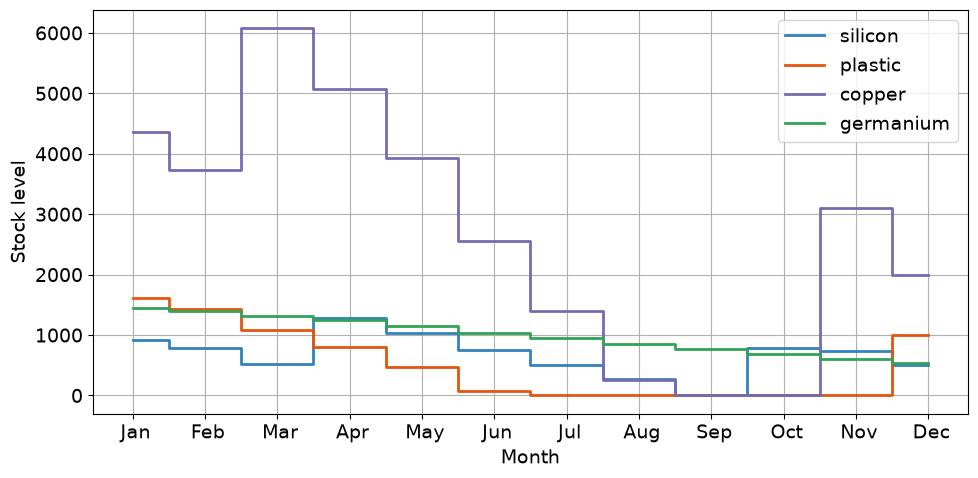

In [5]:
budget = 5000
m = BIMProductAcquisitionAndInventory(
    demand,
    price,
    {"silicon": 1000, "germanium": 1500, "plastic": 1750, "copper": 4800},
    {"silicon": 500, "germanium": 500, "plastic": 1000, "copper": 2000},
    9000,
    budget,
)
results = SOLVER.solve(m)
pyo.assert_optimal_termination(results)


def show_table_of_pyomo_variables(X, I, J):
    return pd.DataFrame.from_records(
        [[pyo.value(X[i, j]) for j in J] for i in I], index=I, columns=J
    ).round(2)


def report_pyomo_solution(m):
    print("\nThe optimal amounts of raw materials to acquire in each month are:")
    display(show_table_of_pyomo_variables(m.x, m.P, m.T))

    print("\nThe corresponding optimal stock levels in each month are:")
    stock = show_table_of_pyomo_variables(m.s, m.P, m.T)
    display(stock)

    print("\nThe stock levels can be visualized as follows")
    plt.rcParams["font.size"] = 14
    colors = plt.get_cmap("tab20c")
    equidistant_colors = [colors(0.0), colors(0.2), colors(0.6), colors(0.4)]
    ax = stock.T.plot(
        drawstyle="steps-mid",
        lw=2,
        grid=True,
        figsize=(10, 5),
        color=equidistant_colors,
    )
    ax.legend(loc="upper right")
    ax.set_xticks(ticks=range(len(stock.columns)))
    ax.set_xticklabels(stock.columns)
    ax.set_xlabel("Month")
    ax.set_ylabel("Stock level")
    plt.tight_layout()
    plt.show()


report_pyomo_solution(m)

Here is a different solution corresponding to the situation where the budget is much lower, namely 2000.



The optimal amounts of raw materials to acquire in each month are:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
silicon,444.67,559.0,0.0,666.67,0.0,400.0,65.05,0.00,125.62,0.0,0.0,0.0
plastic,0.00,0.0,0.0,0.00,0.0,0.0,266.00,327.00,1065.00,0.0,0.0,1310.0
copper,221.33,323.0,2000.0,0.00,1000.0,0.0,0.00,983.65,695.52,2000.0,2000.0,934.5
germanium,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0



The corresponding optimal stock levels in each month are:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
silicon,1356.67,1790.67,1530.67,1980.33,1742.33,1856.33,1673.38,1435.38,1296.0,1003.0,744.0,500.0
plastic,1615.00,1428.00,1087.00,805.00,472.00,68.00,0.00,0.00,718.0,343.0,0.0,1000.0
copper,4575.33,4274.33,5072.33,4074.33,3932.33,2552.33,1388.33,1241.98,713.5,1377.5,2173.5,2000.0
germanium,1453.00,1391.00,1310.00,1245.00,1150.00,1032.00,946.00,857.00,775.0,693.0,609.0,543.0



The stock levels can be visualized as follows


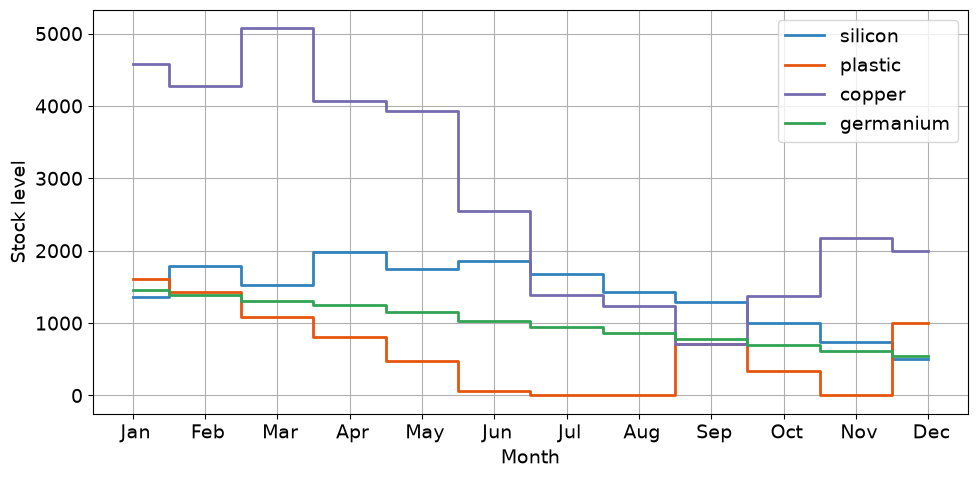

In [6]:
budget = 2000
m = BIMProductAcquisitionAndInventory(
    demand,
    price,
    {"silicon": 1000, "germanium": 1500, "plastic": 1750, "copper": 4800},
    {"silicon": 500, "germanium": 500, "plastic": 1000, "copper": 2000},
    9000,
    budget,
)

results = SOLVER.solve(m)
pyo.assert_optimal_termination(results)

report_pyomo_solution(m)

Looking at the two optimal solutions corresponding to different budgets, we can note that:

- Both the 5000 and 2000 monthly-budget models allow fractional purchases; neither model imposes integrality.
- The 5000 budget is binding in November. Its total cost is 21,152.655, compared with 21,113.4 when the monthly budget constraints are removed, so it does affect the optimum.
- Lowering the monthly budget to 2000 further restricts the purchasing plan. A monthly budget of 1900 makes this instance infeasible.


### A more parsimonious model

We can create a more parsimonious model with fewer variables by expressing the stock levels $s_{pt}$ in terms of the acquisition variables $x_{pt}$. The initial stock and monthly balance equations determine each stock level recursively. The second implementation therefore uses a Pyomo `Expression` for $s_{pt}$ and keeps its nonnegativity as an explicit constraint. Both implementations describe the same feasible acquisition plans and total costs. Here is the corresponding implementation in Pyomo:


In [7]:
def BIMProductAcquisitionAndInventory_v2(
    demand, acquisition_price, existing, desired, stock_limit, month_budget
):
    m = pyo.ConcreteModel("BIM product acquisition and inventory v2")

    periods = demand.columns
    products = demand.index
    first = periods[0]
    prev = {j: i for i, j in zip(periods, periods[1:])}
    last = periods[-1]

    m.T = pyo.Set(initialize=periods)
    m.P = pyo.Set(initialize=products)
    m.PT = m.P * m.T  # to avoid internal set bloat

    m.x = pyo.Var(m.PT, domain=pyo.NonNegativeReals)

    @m.Param(m.PT)
    def pi(m, p, t):
        return acquisition_price.loc[p, t]

    @m.Param(m.PT)
    def h(m, p, t):
        return 0.05  # the holding cost

    @m.Param(m.PT)
    def delta(m, p, t):
        return demand.loc[p, t]

    @m.Expression(m.PT)
    def s(m, p, t):
        if t == first:
            return existing[p] + m.x[p, t] - m.delta[p, t]
        return m.x[p, t] + m.s[p, prev[t]] - m.delta[p, t]

    @m.Constraint(m.PT)
    def non_negative_stock(m, p, t):
        return m.s[p, t] >= 0

    @m.Expression()
    def acquisition_cost(m):
        return pyo.quicksum(m.pi[p, t] * m.x[p, t] for p in m.P for t in m.T)

    @m.Expression()
    def inventory_cost(m):
        return pyo.quicksum(m.h[p, t] * m.s[p, t] for p in m.P for t in m.T)

    @m.Objective(sense=pyo.minimize)
    def total_cost(m):
        return m.acquisition_cost + m.inventory_cost

    @m.Constraint(m.P)
    def finish(m, p):
        return m.s[p, last] >= desired[p]

    @m.Constraint(m.T)
    def inventory(m, t):
        return pyo.quicksum(m.s[p, t] for p in m.P) <= stock_limit

    @m.Constraint(m.T)
    def budget(m, t):
        return pyo.quicksum(m.pi[p, t] * m.x[p, t] for p in m.P) <= month_budget

    return m


The optimal amounts of raw materials to acquire in each month are:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
silicon,444.67,559.0,0.0,666.67,0.0,400.0,56.88,0.0,133.79,0.0,0.0,0.0
plastic,0.00,0.0,0.0,0.00,0.0,0.0,593.00,0.0,1065.00,0.0,0.0,1310.0
copper,221.33,323.0,2000.0,0.00,1000.0,0.0,0.00,1000.0,679.17,2000.0,2000.0,934.5
germanium,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0



The corresponding optimal stock levels in each month are:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
silicon,1356.67,1790.67,1530.67,1980.33,1742.33,1856.33,1665.21,1427.21,1296.0,1003.0,744.0,500.0
plastic,1615.00,1428.00,1087.00,805.00,472.00,68.00,327.00,0.00,718.0,343.0,0.0,1000.0
copper,4575.33,4274.33,5072.33,4074.33,3932.33,2552.33,1388.33,1258.33,713.5,1377.5,2173.5,2000.0
germanium,1453.00,1391.00,1310.00,1245.00,1150.00,1032.00,946.00,857.00,775.0,693.0,609.0,543.0



The stock levels can be visualized as follows


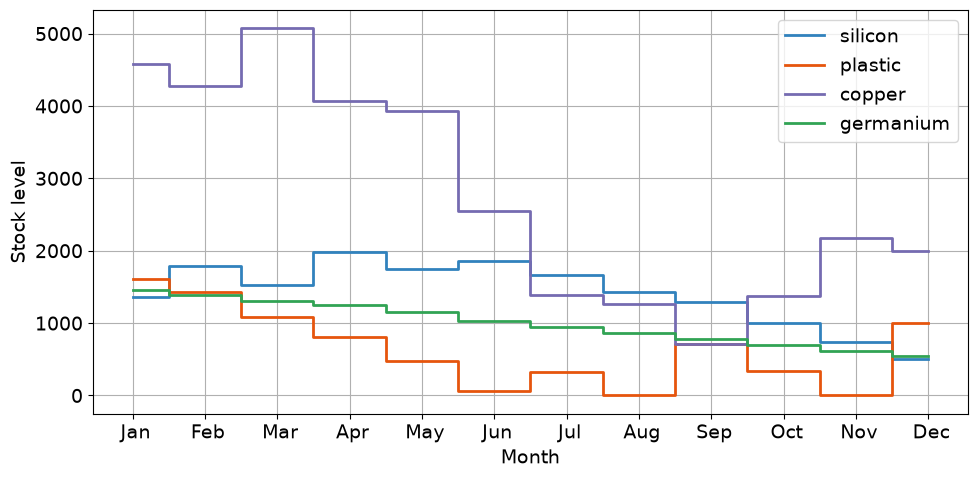

In [8]:
m = BIMProductAcquisitionAndInventory_v2(
    demand,
    price,
    {"silicon": 1000, "germanium": 1500, "plastic": 1750, "copper": 4800},
    {"silicon": 500, "germanium": 500, "plastic": 1000, "copper": 2000},
    9000,
    2000,
)
results = SOLVER.solve(m)
pyo.assert_optimal_termination(results)
report_pyomo_solution(m)

### Checking an infeasible budget

The monthly budget of 1900 discussed above makes the model infeasible. To inspect this outcome, solve with `load_solutions=False` and read the termination condition before attempting to load any solution. The following cell reports that condition without reading acquisition or stock values.

In [9]:
infeasible_plan = BIMProductAcquisitionAndInventory(
    demand,
    price,
    {"silicon": 1000, "germanium": 1500, "plastic": 1750, "copper": 4800},
    {"silicon": 500, "germanium": 500, "plastic": 1000, "copper": 2000},
    9000,
    1900,
)
infeasible_results = SOLVER.solve(infeasible_plan, load_solutions=False)
print("Termination condition:", infeasible_results.solver.termination_condition)

Termination condition: infeasible
